# 1. Libraries

In [1]:
# Import pandas
import pandas as pd

# Import numpy
import numpy as np

# Import seaborn for plotting
import seaborn as sns

# Set style of seaborn library 
sns.set_style("darkgrid")

# Import matplotlib for plotting
from matplotlib import pyplot as plt

# 2. Modules

In [2]:
from data_module import *

from evaluation_module import *

from linear_module import *

# 3. Raw Data

### 3.1 Specification

In [3]:
# Specify time period 
Start = "01/31/1986" 
End = "12/31/2018" 

# Define feature variables 
Features_v = ["Momentum_12_1M", "BookToPrice", "Mcap_BMI_USD", "ROA", "Reversal_1M", "dShsOut_24m",
              "Beta_36M", "dAssets12M", "DividendYield", "DtD_Book", "EarningsToPrice", "EP_FWD_FY1",
              "LiabChangeToAssets", "LiabToAssets", "NetPayoutYield", "ResMom_12_1M_index",
              "Reversal_60_12M", "ROE", "SalesToPrice", "SeaRet5y", "Volatility_36M"]

# Define return variable 
Return_v = "TotalReturnUSD"

# Define market size variable 
Size_v = "Mcap_BMI_USD"

# Specify method (rolling or expanding)
Method = "expanding"  

# Specify after how many month the model is refitted 
Refit = 12

# Specify years of rolling window/min years of expanding method
Years = 10

# Specify number of portfolios for backtesting
N = 10

# Specify validation method: walk-forward (wf) or blocking walk-forward (bwf)
Validation = "wf"

# Specify the years used for validation.
Val_size=1

# Specify number of splits for validation
N_splits=3

### 3.2 Import 

In [4]:
# Import data 
Features, Return, Response, Size = import_data(Features=Features_v, 
                                               Return=Return_v, 
                                               Size=Size_v, 
                                               Start=Start, 
                                               End=End)

# 4. Data Processing

### 4.1 Take log of Size feature

In [5]:
# Take log of size variable
Features.loc[:,"Mcap_BMI_USD"] = Features.loc[:,"Mcap_BMI_USD"].apply(np.log)

# Rename column
Features.rename(columns={"Mcap_BMI_USD":"log_Mcap_BMI_USD"}, inplace=True)

### 4.2 Concat Data and drop NAs

In [6]:
# Concat variables
Data = pd.concat([Features, Return, Response, Size], axis=1)

# Drop inf and NAs
Data = Data.replace([np.inf, -np.inf], np.nan).dropna(how="any")

### 4.3 Winsorize features

In [7]:
# Winsorize features 
Data = winsorize_panel(Panel_Data=Data, 
                       Features=Features.columns, 
                       Upper=0.01, 
                       Lower=0.01)

### 4.4 Show Statistics

In [8]:
# Compute statistics
Data_stats = stats_panel(Panel_Data=Data, 
                         Variables=list(Features.columns)+[Return_v])

# Show statistics
Data_stats

,Avg,Std,N
Momentum_12_1M,0.12,0.39,4177
BookToPrice,0.64,0.48,4177
log_Mcap_BMI_USD,6.64,1.49,4177
ROA,0.03,0.09,4177
Reversal_1M,0.01,0.10,4177
dShsOut_24m,0.03,0.09,4177
Beta_36M,1.05,0.71,4177
dAssets12M,1.13,0.29,4177
DividendYield,1.92,2.15,4177
DtD_Book,4.68,2.03,4177


### 4.5 Demean Return

In [ ]:
# Demean return variable
Data = demean(Data=Data, Variable=['TotalReturnUSD t+1', 'TotalReturnUSD'])

# 5. Fama-MacBeth

### 5.1 Specification

In [9]:
# Define features for Fama-MacBeth
FMB_raw_Features = ["Momentum_12_1M", "BookToPrice", "log_Mcap_BMI_USD", "ROA", "Reversal_1M", "dShsOut_24m",
                    "Beta_36M", "dAssets12M", "DividendYield", "DtD_Book", "EarningsToPrice", "EP_FWD_FY1",
                    "LiabChangeToAssets", "LiabToAssets", "NetPayoutYield", "ResMom_12_1M_index",
                    "Reversal_60_12M", "ROE", "SalesToPrice", "SeaRet5y", "Volatility_36M"]

### 5.2 Data

In [10]:
# Gather data
FMB_raw_Data = gather_data(Data=Data,
                           Features=FMB_raw_Features)

# Compute statistics
FMB_raw_Data_stats = stats_panel(Panel_Data=FMB_raw_Data, 
                                 Variables=FMB_raw_Features+[Return_v])

# Show statistics
FMB_raw_Data_stats

,Avg,Std,N
Momentum_12_1M,0.12,0.39,4177
BookToPrice,0.64,0.48,4177
log_Mcap_BMI_USD,6.64,1.49,4177
ROA,0.03,0.09,4177
Reversal_1M,0.01,0.10,4177
dShsOut_24m,0.03,0.09,4177
Beta_36M,1.05,0.71,4177
dAssets12M,1.13,0.29,4177
DividendYield,1.92,2.15,4177
DtD_Book,4.68,2.03,4177


### 5.3 Cross-sectional regressions

In [11]:
# Perform Cross-sectional regressions and compute statistics
FMB_raw_coef_mean, \
FMB_raw_inter_mean, \
Years, \
FMB_raw_reg_stats         = fmb_reg(Data=FMB_raw_Data,                # data 
                            Features=FMB_raw_Features,        # feature variables 
                            Response=Response.columns,        # response variable 
                            Method=Method,                    # rolling or expanding method                                 
                            Years=Years,                      # years of rolling window/min years of expanding method
                            Refit=Refit,                      # months after which the model is refitted
                            Stats=True,                       # whether to compute summary statistics
                            Include_inter=True,               # whether to include intercept 
                            Data_stats=FMB_raw_Data_stats,    # summary statistics for data
                            maxlags=4)                        # newey-west adjustment

# Show statistics for regressions
FMB_raw_reg_stats

,Slope,t-stat,Stocks
Momentum_12_1M,0.74,3.02,4177
BookToPrice,0.12,1.04,4177
log_Mcap_BMI_USD,-0.00,-0.04,4177
ROA,0.31,0.43,4177
Reversal_1M,-1.99,-3.92,4177
dShsOut_24m,-1.18,-1.38,4177
Beta_36M,0.01,0.13,4177
dAssets12M,-0.14,-1.40,4177
DividendYield,-0.01,-0.52,4177
DtD_Book,0.01,0.22,4177


### 5.4 Plot slopes

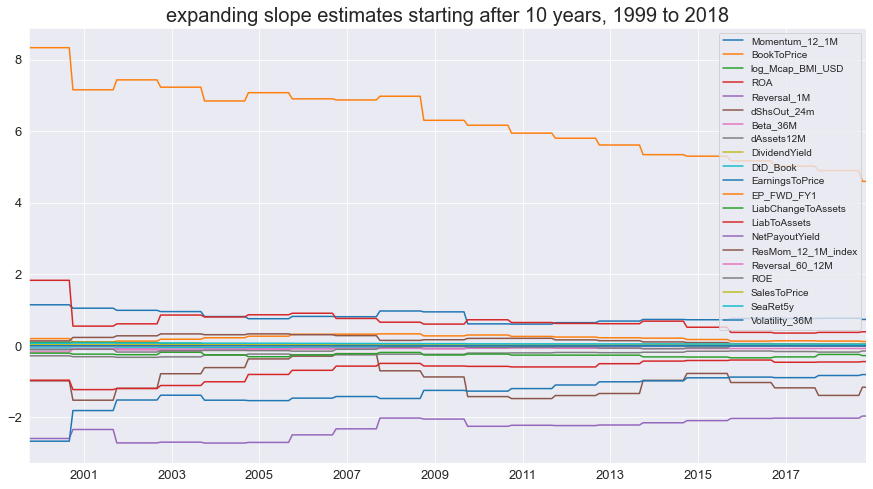

In [12]:
# Plot slopes
plot_coef(Coef=FMB_raw_coef_mean, 
          Method=Method, 
          Years=Years)   

### 5.5 Prediction

In [34]:
# Make predictions and compute statistics
FMB_raw_Pre, FMB_raw_Pre_stats = fmb_pred(Data=FMB_raw_Data,
                                          Coef=FMB_raw_coef_mean,
                                          Inter=FMB_raw_inter_mean,
                                          Features=FMB_raw_Features,
                                          Stats=True)

# Show summary statistic for predictions
FMB_raw_Pre_stats

,Prediction
Avg,0.722130
Std,0.764986
p10,-0.143631
p90,1.559653


### 5.6 Evaluation

In [36]:
# Create evaluation table
FMB_raw_Eval_Data = eval_data(Data=FMB_raw_Data, 
                              Predictions=FMB_raw_Pre, 
                              Return=Return_v, 
                              Size=Size_v)

# Create Portfolios
FMB_raw_Eval_Port, FMB_raw_Eval_Port_cRet = portfolios(Eval_Data=FMB_raw_Eval_Data, N=N)

# Regress return on prediction and compute statistics
FMB_raw_Eval_Reg = linear_eval_reg(Eval_Data=FMB_raw_Eval_Data, Rounding=2)

# Show statistic
FMB_raw_Eval_Reg

,Prediction
Slope,0.543796
S.E.,0.073833
t-stat,7.365228


### cum. Outperformance

In [ ]:
FMB_raw_Eval_Port_cRet[FMB_raw_Eval_Port_cRet.columns].plot.line(
figsize=[15,8], 
fontsize=13,
title ="Cum. Outperformance, %.0f to %.0f" 
% (FMB_raw_Eval_Data.index[0][0].year, FMB_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Returns vs Predictions

In [ ]:
FMB_raw_Eval_Port.loc[:,["Return","Prediction"]].iloc[:-1].plot.bar(
figsize=[15,8],
fontsize=13,
title ="Monthly Returns vs Predictions, %.0f to %.0f" 
% (FMB_raw_Eval_Data.index[0][0].year, FMB_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Standard deviations

In [ ]:
FMB_raw_Eval_Port.loc[:,"Std"].iloc[:-1].plot.bar(
figsize=[15,8], 
fontsize=13,
title ="Monthly Standard deviations, %.0f to %.0f" 
% (FMB_raw_Eval_Data.index[0][0].year, FMB_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Information Ratios

In [ ]:
FMB_raw_Eval_Port.loc[:,"IR"].iloc[:-1].plot.bar(
figsize=[15,8],
fontsize=13,
title ="Annualized Information Ratios, %.0f to %.0f" 
% (FMB_raw_Eval_Data.index[0][0].year, FMB_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### 5.7 Store Model

In [ ]:
# Store dataframes 
FMB_raw_Eval_Port.to_pickle("FMB_raw_Eval_Port")
FMB_raw_Eval_Reg.to_pickle("FMB_raw_Eval_Reg")
FMB_raw_Eval_Port_cRet.to_pickle("FMB_raw_Eval_Port_cRet")

# 6. Pooled OLS

### 6.1 Specification

In [ ]:
# Define features for Pooled OLS
Pool_raw_Features = ["Momentum_12_1M", "BookToPrice", "log_Mcap_BMI_USD", "ROA", "Reversal_1M", "dShsOut_24m",
                    "Beta_36M", "dAssets12M", "DividendYield", "DtD_Book", "EarningsToPrice", "EP_FWD_FY1",
                    "LiabChangeToAssets", "LiabToAssets", "NetPayoutYield", "ResMom_12_1M_index",
                    "Reversal_60_12M", "ROE", "SalesToPrice", "SeaRet5y", "Volatility_36M"]

### 6.2 Data

In [ ]:
# Gather data
Pool_raw_Data = gather_data(Data=Data, 
                            Features=Pool_raw_Features)

# Compute statistics
Pool_raw_Data_stats = stats_panel(Panel_Data=Pool_raw_Data, 
                                  Variables=Pool_raw_Features+[Return_v])

# Show statistics
Pool_raw_Data_stats

### 6.3 Regressions + Predictions

In [ ]:
# Perform pooled regressions and make precitions 
Pool_raw_Pre, \
Pool_raw_Coef, \
Pool_raw_pred_stats, \
Years = panel_reg(Data=Pool_raw_Data,    # data 
        Features=Pool_raw_Features,      # feature variables 
        Response=Response.columns,       # response variable 
        Method=Method,                   # rolling or expanding method
        Years=Years,                     # years of rolling window/min years of expanding 
        Refit=Refit,                     # months after which the model is refitted 
        Stats=True,                      # whether to compute summary statistics
        Include_inter=True)              # whether to include intercept 

# Show stats for predictions
Pool_raw_pred_stats

### 6.4 Plot slopes

In [ ]:
# Plot slopes
plot_coef(Coef=Pool_raw_Coef, 
          Method=Method, 
          Years=Years)   

 ### 6.5 Evaluation

In [ ]:
# Create evaluation table
Pool_raw_Eval_Data = eval_data(Data=Pool_raw_Data, 
                               Predictions=Pool_raw_Pre, 
                               Return=Return_v, 
                               Size=Size_v)

# Create Portfolios
Pool_raw_Eval_Port, Pool_raw_Eval_Port_cRet = portfolios(Eval_Data=Pool_raw_Eval_Data, N=N)

# Regress return on prediction and compute statistics
Pool_raw_Eval_Reg = linear_eval_reg(Eval_Data=Pool_raw_Eval_Data)

# Show statistic
Pool_raw_Eval_Reg

### cum. Returns

In [ ]:
Pool_raw_Eval_Port_cRet[Pool_raw_Eval_Port_cRet.columns].plot.line(
figsize=[15,8],
fontsize=13,
title ="Cum. Returns, %.0f to %.0f" 
% (Pool_raw_Eval_Data.index[0][0].year, Pool_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Returns vs Predictions

In [ ]:
Pool_raw_Eval_Port.loc[:,["Return","Prediction"]].iloc[:-1].plot.bar(
figsize=[15,8], 
fontsize=13,
title ="Monthly Returns vs Predictions, %.0f to %.0f" 
% (Pool_raw_Eval_Data.index[0][0].year, Pool_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Standard deviations

In [ ]:
Pool_raw_Eval_Port.loc[:,"Std"].iloc[:-1].plot.bar(
figsize=[15,8], 
fontsize=13,
title ="Monthly Standard deviations, %.0f to %.0f" 
% (Pool_raw_Eval_Data.index[0][0].year, Pool_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Sharpe Ratios

In [ ]:
Pool_raw_Eval_Port.loc[:,"IR"].iloc[:-1].plot.bar(
figsize=[15,8],
fontsize=13,
title ="Annualized Sharpe Ratios, %.0f to %.0f" 
% (Pool_raw_Eval_Data.index[0][0].year, Pool_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### 6.6 Store Model

In [ ]:
# Store dataframes 
Pool_raw_Eval_Port.to_pickle("Pool_raw_Eval_Port")
Pool_raw_Eval_Reg.to_pickle("Pool_raw_Eval_Reg")
Pool_raw_Eval_Port_cRet.to_pickle("Pool_raw_Eval_Port_cRet")

# 7 Time Fixed Effect Model

### 7.1 Specification

In [ ]:
# Define features for Fixed Effect Model
TFE_raw_Features = ["Momentum_12_1M", "BookToPrice", "log_Mcap_BMI_USD", "ROA", "Reversal_1M", "dShsOut_24m",
                    "Beta_36M", "dAssets12M", "DividendYield", "DtD_Book", "EarningsToPrice", "EP_FWD_FY1",
                    "LiabChangeToAssets", "LiabToAssets", "NetPayoutYield", "ResMom_12_1M_index",
                    "Reversal_60_12M", "ROE", "SalesToPrice", "SeaRet5y", "Volatility_36M"]

### 7.2 Data

In [ ]:
# Gather data
TFE_raw_Data = gather_data(Data=Data, 
                           Features=TFE_raw_Features)

# Compute statistics
TFE_raw_Data_stats = stats_panel(Panel_Data=TFE_raw_Data, 
                                 Variables=TFE_raw_Features+[Return_v])

# Show statistics
TFE_raw_Data_stats

### 7.3 Regressions + Predictions

In [ ]:
# Perform TFE regressions and make precitions 
TFE_raw_Pre, \
TFE_raw_Coef, \
TFE_raw_pred_stats, \
Years = panel_reg(Data=TFE_raw_Data,            # data 
                  Features=TFE_raw_Features,    # feature variables 
                  Response=Response.columns,    # response variable
                  Method=Method,                # rolling or expanding method
                  Years=Years,                  # years of rolling window/min years of expanding 
                  Refit=Refit,                  # months after which the model is refitted
                  Stats=True,                   # whether to compute summary statistics
                  Include_inter=True)           # whether to include intercept 
                  
# Show stats for predictions
TFE_raw_pred_stats

### 7.4 Plot slopes 

In [ ]:
# Plot slopes
plot_coef(Coef=TFE_raw_Coef, 
          Method=Method, 
          Years=Years)   

### 7.5 Evaluation

In [ ]:
# Create evaluation table
TFE_raw_Eval_Data = eval_data(Data=TFE_raw_Data, 
                              Predictions=TFE_raw_Pre, 
                              Return=Return_v, 
                              Size=Size_v)

# Create Portfolios
TFE_raw_Eval_Port, TFE_raw_Eval_Port_cRet = portfolios(Eval_Data=TFE_raw_Eval_Data, N=N)

# Regress return on prediction and compute statistics
TFE_raw_Eval_Reg = linear_eval_reg(Eval_Data=TFE_raw_Eval_Data)

# Show statistic
TFE_raw_Eval_Reg

### cum. Outperformance

In [ ]:
TFE_raw_Eval_Port_cRet[TFE_raw_Eval_Port_cRet.columns].plot.line(
figsize=[15,8],
fontsize=13,                                                              
title ="Cum. Outperformance, %.0f to %.0f" 
% (TFE_raw_Eval_Data.index[0][0].year, TFE_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Returns vs Predictions

In [ ]:
TFE_raw_Eval_Port.loc[:,["Return","Prediction"]].iloc[:-1].plot.bar(
figsize=[15,8],
fontsize=13,
title ="Monthly Returns vs Predictions, %.0f to %.0f" 
% (TFE_raw_Eval_Data.index[0][0].year, TFE_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Standard deviations

In [ ]:
TFE_raw_Eval_Port.loc[:,"Std"].iloc[:-1].plot.bar(
figsize=[15,8], 
fontsize=13,
title ="Monthly Standard deviations, %.0f to %.0f" 
% (TFE_raw_Eval_Data.index[0][0].year, TFE_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Information Ratios

In [ ]:
TFE_raw_Eval_Port.loc[:,"IR"].iloc[:-1].plot.bar(
figsize=[15,8],
fontsize=13,
title ="Annualized Information Ratios, %.0f to %.0f" 
% (TFE_raw_Eval_Data.index[0][0].year, TFE_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### 7.6 Store model

In [ ]:
# Store dataframes 
TFE_raw_Eval_Port.to_pickle("TFE_raw_Eval_Port")
TFE_raw_Eval_Reg.to_pickle("TFE_raw_Eval_Reg")
TFE_raw_Eval_Port_cRet.to_pickle("TFE_raw_Eval_Port_cRet")

# 8. Penalized Linear

### 8.1 Specification

In [ ]:
# Define features for penalized linear Model
PL_raw_Features = ["Momentum_12_1M", "BookToPrice", "log_Mcap_BMI_USD", "ROA", "Reversal_1M", "dShsOut_24m",
                   "Beta_36M", "dAssets12M", "DividendYield", "DtD_Book", "EarningsToPrice", "EP_FWD_FY1",
                   "LiabChangeToAssets", "LiabToAssets", "NetPayoutYield", "ResMom_12_1M_index",
                   "Reversal_60_12M", "ROE", "SalesToPrice", "SeaRet5y", "Volatility_36M"]

### 8.2 Data

In [ ]:
# Gather data
PL_raw_Data = gather_data(Data=Data,
                          Features=PL_raw_Features).astype(float)

# Compute statistics
PL_raw_Data_stats = stats_panel(Panel_Data=PL_raw_Data, 
                                Variables=PL_raw_Features+[Return_v])

# Show statistics
PL_raw_Data_stats

# Elnet

### 8.3 Hyperparameter

Importtant Hyperparameters:
1. Scaling between l1 and l2 penalties (l1_ratio)
2. Alpha (alpha)

### 8.4 Penalized Linear regressions

In [ ]:
# Perform elastic net regressions and make precitions 
Elnet_sc_Pre, \
Elnet_sc_Summary, \
Elnet_sc_Pre_stats, \
Years = pl(Data=PL_raw_Data,             # data 
           Features=PL_raw_Features,     # feature variables 
           Response=Response.columns,    # response variable  
           Method=Method,                # rolling or expanding method
           Years=Years,                  # years of rolling window/min years of expanding 
           Refit=Refit,                  # months after which the model is refitted
           Stats=True,                   # whether to compute summary statistics
           Include_inter=True,           # whether to include intercept 
           Validation=Validation,        # walk-forward (wf) or blocking walk-forward (bwf)
           Val_size=Val_size,            # years used for validation
           N_splits=N_splits,            # number of splits            
           Penalty="elnet",              # options for penalty (elnet, lasso, or ridge)
           param_grid={'linear__alpha':[.001, .01],                       # options for alpha  
                            'linear__l1_ratio':[.2, .4, .6, .8]})   # options for l1 ratio 
                    
                                    
# Show stats for predictions
Elnet_sc_Pre_stats

### 8.5 Plots 

### Plot slopes  

In [ ]:
# Plot slopes
plot_coef(Coef=Elnet_sc_Summary[PL_raw_Features], 
          Method=Method, 
          Years=Years)   

### Slope Averages

In [ ]:
Elnet_sc_Summary[PL_raw_Features].apply(np.mean, axis=0).sort_values().plot.barh(
figsize=[8,10], 
cmap="Blues_r", 
fontsize=13,                                                                  
title ="Slope averages, %.0f to %.0f" % (Elnet_sc_Summary.index[0].year, Elnet_sc_Summary.index[-1].year)).title.set_size(20);

### Selected Features

In [ ]:
sns.set(font_scale = 1.3)
plt.figure(figsize = (15,8))
sns.heatmap(Elnet_sc_Summary[PL_raw_Features] != 0, cmap="Blues",  cbar=False).set_title(
'Selected Features, %.0f to %.0f' % (Elnet_sc_Summary.index[0].year, Elnet_sc_Summary.index[-1].year), size=20);

### Number of selected Features 

In [ ]:
Elnet_sc_Summary["N"].plot.bar(
figsize=[15,8], 
cmap="Blues_r",
fontsize=13,
title ="Number of selected Features, %.0f to %.0f" % (Elnet_sc_Summary.index[0].year, Elnet_sc_Summary.index[-1].year)).title.set_size(20);

### 8.6 Evaluation

In [ ]:
# Create evaluation table
Elnet_sc_Eval_Data = eval_data(Data=PL_raw_Data, 
                               Predictions=Elnet_sc_Pre, 
                               Return=Return_v, 
                               Size=Size_v)

# Create Portfolios
Elnet_sc_Eval_Port, Elnet_sc_Eval_Port_cRet = portfolios(Eval_Data=Elnet_sc_Eval_Data, N=N)

# Regress return on prediction and compute statistics
Elnet_sc_Eval_Reg = linear_eval_reg(Eval_Data=Elnet_sc_Eval_Data)

# Show statistic
Elnet_sc_Eval_Reg

### cum. Outperformance 

In [ ]:
Elnet_sc_Eval_Port_cRet[Elnet_sc_Eval_Port_cRet.columns].plot.line(
figsize=[15,8],
fontsize=13,
title ="Cum. Outperformance, %.0f to %.0f" 
% (Elnet_sc_Eval_Data.index[0][0].year, Elnet_sc_Eval_Data.index[-1][0].year)).title.set_size(20);

### Returns vs Predictions

In [ ]:
Elnet_sc_Eval_Port.loc[:,["Return","Prediction"]].iloc[:-1].plot.bar(
figsize=[15,8],
fontsize=13,
title ="Monthly Returns vs Predictions, %.0f to %.0f" 
% (Elnet_sc_Eval_Data.index[0][0].year, Elnet_sc_Eval_Data.index[-1][0].year)).title.set_size(20);

### Standard deviations 

In [ ]:
Elnet_sc_Eval_Port.loc[:,"Std"].iloc[:-1].plot.bar(
figsize=[15,8], 
fontsize=13,    
title ="Monthly Standard deviations, %.0f to %.0f" 
% (Elnet_sc_Eval_Data.index[0][0].year, Elnet_sc_Eval_Data.index[-1][0].year)).title.set_size(20);

### Information Ratios 

In [ ]:
Elnet_sc_Eval_Port.loc[:,"IR"].iloc[:-1].plot.bar(
figsize=[15,8],
fontsize=13,
title ="Annualized Information Ratios, %.0f to %.0f" 
% (Elnet_sc_Eval_Data.index[0][0].year, Elnet_sc_Eval_Data.index[-1][0].year)).title.set_size(20);

### 8.7 Store model

In [ ]:
# Store dataframes 
Elnet_sc_Eval_Port.to_pickle("Elnet_sc_Eval_Port")
Elnet_sc_Eval_Reg.to_pickle("Elnet_sc_Eval_Reg")
Elnet_sc_Eval_Port_cRet.to_pickle("Elnet_sc_Eval_Port_cRet")

# Lasso

### 8.3 Hyperparameter

Importtant Hyperparameters:
1. Alpha (alpha)

### 8.4 Penalized Linear regressions

In [ ]:
# Perform lasso regressions and make precitions 
Lasso_sc_Pre, \
Lasso_sc_Summary, \
Lasso_sc_Pre_stats, \
Years = pl(Data=PL_raw_Data,             # data
           Features=PL_raw_Features,     # feature variables 
           Response=Response.columns,    # response variable 
           Method=Method,                # rolling or expanding method
           Years=Years,                  # years of rolling window/min years of expanding
           Refit=Refit,                  # months after which the model is refitted
           Stats=True,                   # whether to compute summary statistics
           Include_inter=True,           # whether to include intercept 
           Validation=Validation,        # walk-forward (wf) or blocking walk-forward (bwf)
           Val_size=Val_size,            # validation size   
           N_splits=N_splits,            # number of splits          
           Penalty="lasso",              # options for penalty (elnet, lasso, or ridge)
           param_grid={'linear__alpha':[.001, .01]})    # options for alpha  
                                
                            
# Show stats for predictions
Lasso_sc_Pre_stats

### 8.5 Plots 

### Plot slopes  

In [ ]:
# Plot slopes
plot_coef(Coef=Lasso_sc_Summary[PL_raw_Features], 
          Method=Method, 
          Years=Years)      

### Slope Averages

In [ ]:
Lasso_sc_Summary[PL_raw_Features].apply(np.mean, axis=0).sort_values().plot.barh(
figsize=[8,10], 
cmap="Blues_r", 
fontsize=13,                                                                  
title ="Slope averages, %.0f to %.0f" % (Lasso_sc_Summary.index[0].year, Lasso_sc_Summary.index[-1].year)).title.set_size(20);

### Selected Features

In [ ]:
sns.set(font_scale = 1.3)
plt.figure(figsize = (15,8))
sns.heatmap(Lasso_sc_Summary[PL_raw_Features] != 0, cmap="Blues",  cbar=False).set_title(
'Selected Features, %.0f to %.0f' % (Lasso_sc_Summary.index[0].year, Lasso_sc_Summary.index[-1].year), size=20);

### Number of selected Features 

In [ ]:
Lasso_sc_Summary["N"].plot.bar(
figsize=[15,8], 
cmap="Blues_r",
fontsize=13,
title ="Number of selected Features, %.0f to %.0f" % (Lasso_sc_Summary.index[0].year, Lasso_sc_Summary.index[-1].year)).title.set_size(20);

### 8.6 Evaluation

In [ ]:
# Create evaluation table
Lasso_sc_Eval_Data = eval_data(Data=PL_raw_Data, 
                                Predictions=Lasso_sc_Pre, 
                                Return=Return_v, 
                                Size=Size_v)

# Create Portfolios
Lasso_sc_Eval_Port, Lasso_sc_Eval_Port_cRet = portfolios(Eval_Data=Lasso_sc_Eval_Data, N=N)

# Regress return on prediction and compute statistics
Lasso_sc_Eval_Reg = linear_eval_reg(Eval_Data=Lasso_sc_Eval_Data)

# Show statistic
Lasso_sc_Eval_Reg

### cum. Outperformance 

In [ ]:
Lasso_sc_Eval_Port_cRet[Lasso_sc_Eval_Port_cRet.columns].plot.line(
figsize=[15,8],
fontsize=13,
title ="Cum. Outperformance, %.0f to %.0f" 
% (Lasso_sc_Eval_Data.index[0][0].year, Lasso_sc_Eval_Data.index[-1][0].year)).title.set_size(20);

### Returns vs Predictions

In [ ]:
Lasso_sc_Eval_Port.loc[:,["Return","Prediction"]].iloc[:-1].plot.bar(
figsize=[15,8],
fontsize=13,
title ="Monthly Returns vs Predictions, %.0f to %.0f" 
% (Lasso_sc_Eval_Data.index[0][0].year, Lasso_sc_Eval_Data.index[-1][0].year)).title.set_size(20);

### Standard deviations 

In [ ]:
Lasso_sc_Eval_Port.loc[:,"Std"].iloc[:-1].plot.bar(
figsize=[15,8], 
fontsize=13,    
title ="Monthly Standard deviations, %.0f to %.0f" 
% (Lasso_sc_Eval_Data.index[0][0].year, Lasso_sc_Eval_Data.index[-1][0].year)).title.set_size(20);

### Information Ratios 

In [ ]:
Lasso_sc_Eval_Port.loc[:,"IR"].iloc[:-1].plot.bar(
figsize=[15,8],
fontsize=13,
title ="Annualized Information Ratios, %.0f to %.0f" 
% (Lasso_sc_Eval_Data.index[0][0].year, Lasso_sc_Eval_Data.index[-1][0].year)).title.set_size(20);

### 8.7 Store model

In [ ]:
# Store dataframes 
Lasso_sc_Eval_Port.to_pickle("Lasso_sc_Eval_Port")
Lasso_sc_Eval_Reg.to_pickle("Lasso_sc_Eval_Reg")
Lasso_sc_Eval_Port_cRet.to_pickle("Lasso_sc_Eval_Port_cRet")

# Ridge

### 8.3 Hyperparameter

Importtant Hyperparameters:
1. Alpha (alpha)

### 8.4 Penalized Linear regressions

In [ ]:
# Perform Ridge regressions and make precitions 
Ridge_sc_Pre, \
Ridge_sc_Summary, \
Ridge_sc_Pre_stats, \
Years = pl(Data=PL_raw_Data,             # data
           Features=PL_raw_Features,     # feature variables 
           Response=Response.columns,    # response variable  
           Method=Method,                # rolling or expanding method
           Years=Years,                  # years of rolling window/min years of expanding
           Refit=Refit,                  # months after which the model is refitted
           Stats=True,                   # whether to compute summary statistics
           Include_inter=True,           # whether to include intercept 
           Validation=Validation,        # walk-forward (wf) or blocking walk-forward (bwf)
           Val_size=Val_size,            # validation size
           N_splits=N_splits,            # number of splits  
           Penalty="ridge",              # options for penalty (elnet, lasso, or ridge)
           param_grid={'linear__alpha':[.001, .01]})   
                          
# Show stats for predictions
Ridge_sc_Pre_stats

### 8.5 Plots 

### Plot slopes  

In [ ]:
# Plot slopes
plot_coef(Coef=Ridge_sc_Summary[PL_raw_Features], 
          Method=Method, 
          Years=Years)      

### Slope Averages

In [ ]:
Ridge_sc_Summary[PL_raw_Features].apply(np.mean, axis=0).sort_values().plot.barh(
figsize=[8,10], 
cmap="Blues_r", 
fontsize=13,                                                                  
title ="Slope averages, %.0f to %.0f" % (Ridge_sc_Summary.index[0].year, Ridge_sc_Summary.index[-1].year)).title.set_size(20);

### 8.6 Evaluation

In [ ]:
# Create evaluation table
Ridge_sc_Eval_Data = eval_data(Data=PL_raw_Data, 
                                Predictions=Ridge_sc_Pre, 
                                Return=Return_v, 
                                Size=Size_v)

# Create Portfolios
Ridge_sc_Eval_Port, Ridge_sc_Eval_Port_cRet = portfolios(Eval_Data=Ridge_sc_Eval_Data, N=N)

# Regress return on prediction and compute statistics
Ridge_sc_Eval_Reg = linear_eval_reg(Eval_Data=Ridge_sc_Eval_Data)

# Show statistic
Ridge_sc_Eval_Reg

### cum. Outperformance 

In [ ]:
Ridge_sc_Eval_Port_cRet[Ridge_sc_Eval_Port_cRet.columns].plot.line(
figsize=[15,8],
fontsize=13,
title ="Cum. Outperformance, %.0f to %.0f" 
% (Ridge_sc_Eval_Data.index[0][0].year, Ridge_sc_Eval_Data.index[-1][0].year)).title.set_size(20);

### Returns vs Predictions

In [ ]:
Ridge_sc_Eval_Port.loc[:,["Return","Prediction"]].iloc[:-1].plot.bar(
figsize=[15,8],
fontsize=13,
title ="Monthly Returns vs Predictions, %.0f to %.0f" 
% (Ridge_sc_Eval_Data.index[0][0].year, Ridge_sc_Eval_Data.index[-1][0].year)).title.set_size(20);

### Standard deviations 

In [ ]:
Ridge_sc_Eval_Port.loc[:,"Std"].iloc[:-1].plot.bar(
figsize=[15,8], 
fontsize=13,    
title ="Monthly Standard deviations, %.0f to %.0f" 
% (Ridge_sc_Eval_Data.index[0][0].year, Ridge_sc_Eval_Data.index[-1][0].year)).title.set_size(20);

### Information Ratios 

In [ ]:
Ridge_sc_Eval_Port.loc[:,"IR"].iloc[:-1].plot.bar(
figsize=[15,8],
fontsize=13,
title ="Annualized Information Ratios, %.0f to %.0f" 
% (Ridge_sc_Eval_Data.index[0][0].year, Ridge_sc_Eval_Data.index[-1][0].year)).title.set_size(20);

### 8.7 Store model

In [ ]:
# Store dataframes 
Ridge_sc_Eval_Port.to_pickle("Ridge_sc_Eval_Port")
Ridge_sc_Eval_Reg.to_pickle("Ridge_sc_Eval_Reg")
Ridge_sc_Eval_Port_cRet.to_pickle("Ridge_sc_Eval_Port_cRet")

# 9. Comparison

In [ ]:
# Compare models
compare(Models = ["FMB_raw", "Pool_raw", "TFE_raw", "Elnet_sc", "Ridge_sc", "Lasso_sc"], Plot=False, Globals=globals()).plot.bar(
figsize=[15,8],
fontsize=13,
title ="Comparison of linear models, %.0f to %.0f" 
% ((Data.index[0][0] + pd.offsets.BMonthEnd(Years*12)).year, Data.index[-1][0].year)).title.set_size(20);